# Function 1 - Week 5: Cohort Exploration

#### Review of Measured Outputs and Input Coverage up to and including Week 4 return, received on **23 October 2026**. Retained cohort snapshot: **20 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review, remaining_exploration_queries
from plot_helpers import (
    PLOT_CONFIG, plot_sampling_gaps,
    plot_observed_terrain, plot_fixed_exploration_progression,
)
function_shared_dir = shared_dir.parent / "Function_1" / "FunctionSpecificShared"
if str(function_shared_dir) not in sys.path:
    sys.path.insert(0, str(function_shared_dir))

from function_1_plots import plot_output_number_line
from function_1_model_helpers import signed_log
from cohort_review_helpers import load_cohort_review

In [2]:
# Settings for this run. Keep the saved planning coordinates at full precision.
FUNCTION_NUMBER = 1
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}

ANALYSIS_DIR = Path.cwd().resolve()
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK} cohort"

FIRST_PLAN_WEEK = 2
PORTAL_DECIMALS = 6
PLANNED_QUERIES = pd.DataFrame([
    [0.15308205385104573, 0.13395525138390008],
    [0.7818589422435338, 0.0256071460565101],
    [0.12954929624948736, 0.822189245547224],
    [0.9121401448788213, 0.8617829948823881],
], columns=INPUT_COLUMNS)

SAMPLING_GAP_SIZE = (7.6 * 0.75, 6.1 * 0.75)
TERRAIN_SETTINGS = dict(
    relief=0.16, width=850, height=560,
    camera=dict(eye=dict(x=-1.05, y=-1.35, z=0.9)),
    show_reset=True,
)
TERRAIN_SCALE = 1e-200
TERRAIN_TICKS = (-1e-3, 0.0, 1e-13)
OFFICIAL_DATA_PATH = ANALYSIS_DIR.parent / "official" / "observations.csv"
EXPECTED_PEER_COUNT = 6
PEER_ROUND_MAX = 2

In [3]:
# Validate the snapshot before plotting it.
review = load_cohort_review(
    DATA_PATH, OFFICIAL_DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
    expected_peer_count=EXPECTED_PEER_COUNT, peer_round_max=PEER_ROUND_MAX,
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,y,output_rank
13,round-04,4,0.129549,0.822189,-9.545890e-172,10


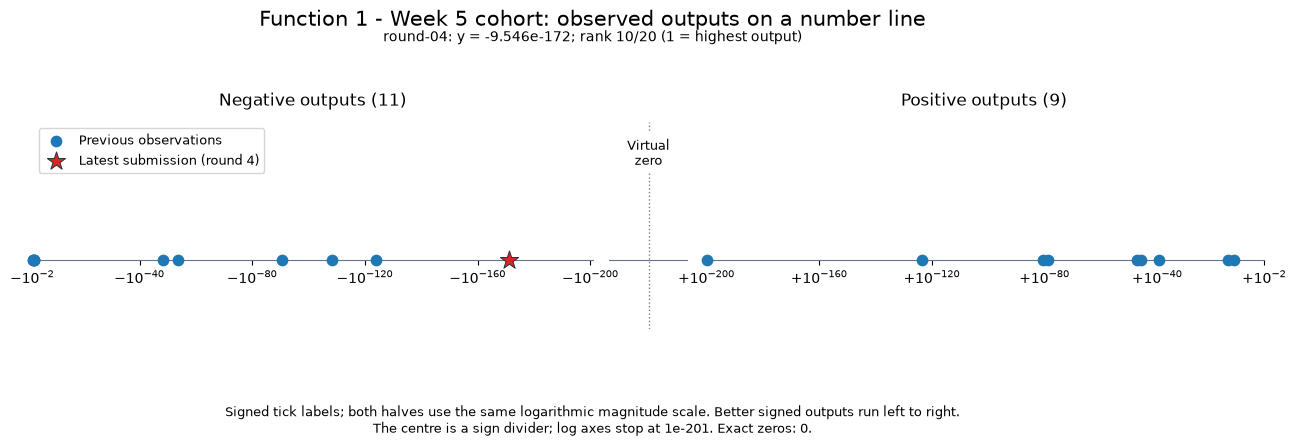

In [4]:
# Outputs on their original linear scale.
plot_output_number_line(
    review, title=f"{TITLE}: observed outputs on a number line",
    save_to=FIGURES_DIR / "output-number-line.png",
)

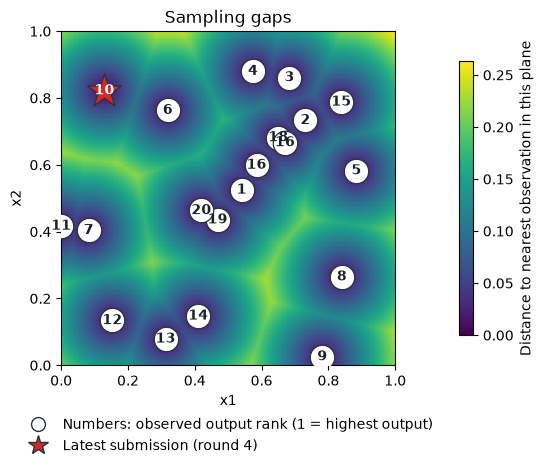

In [5]:
# Measured ranks and sampling gaps in the two-input square.
plot_sampling_gaps(
    review["plot_data"], pair=INPUT_COLUMNS,
    highlight=review["latest_mask"],
    highlight_label=f"Latest submission (round {review['latest_round']})",
    figsize=SAMPLING_GAP_SIZE, save_to=FIGURES_DIR / "sampling-gaps.png",
)

In [6]:
# The terrain joins observed signed-log heights; it does not fit a model.
terrain_fig = plot_observed_terrain(
    review["inputs"].to_numpy(), review["outputs"].to_numpy(),
    title=f"Function {FUNCTION_NUMBER}: observed-output terrain ({len(review['data'])} samples)",
    heights=signed_log(review["outputs"].to_numpy(), scale=TERRAIN_SCALE),
    height_axis=dict(title="Output y (signed log)", tickmode="array",
        tickvals=signed_log(TERRAIN_TICKS, scale=TERRAIN_SCALE),
        ticktext=[f"{value:.0e}" if value else "0" for value in TERRAIN_TICKS]),
    height_description="signed-log heights", save_to=FIGURES_DIR / "observed-output-terrain.html",
    **TERRAIN_SETTINGS,
)
terrain_fig.show(config={**PLOT_CONFIG, "responsive": TERRAIN_SETTINGS["width"] is None})

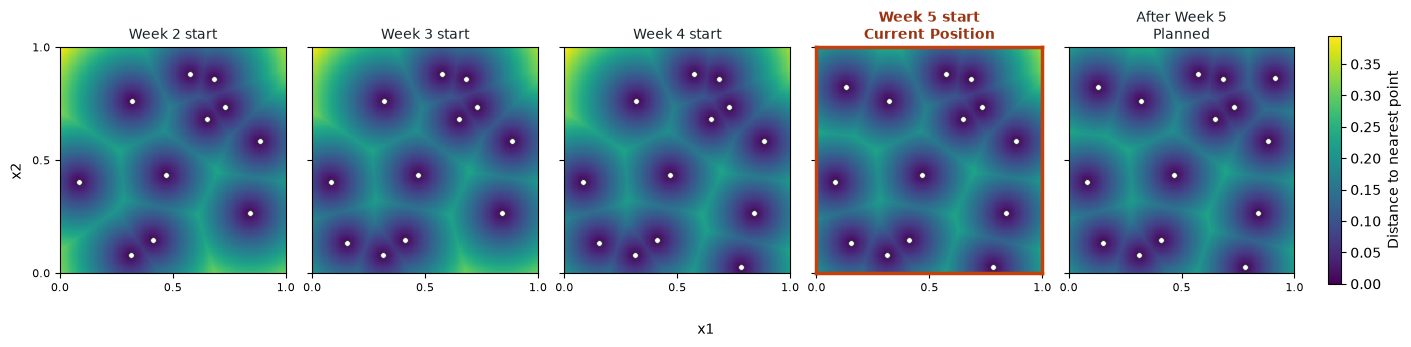

In [7]:
# Keep peer round labels out of the official fixed-plan timeline.
plot_fixed_exploration_progression(
    review["own_data"], PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK,
    save_to=FIGURES_DIR / "fixed-exploration-progression.png",
)

In [8]:
# Preserve the final saved Week 5 query, rounded only for the portal string.
remaining_plan = remaining_exploration_queries(
    PLANNED_QUERIES, current_week=CURRENT_WEEK,
    first_plan_week=FIRST_PLAN_WEEK, precision=PORTAL_DECIMALS,
)
display(remaining_plan.style.format({
    column: f"{{:.{PORTAL_DECIMALS}f}}" for column in INPUT_COLUMNS
}))

,x1,x2,Portal input
Week,,,
5,0.912140,0.861783,0.912140-0.861783


In [9]:
# Raw signed values remain scientific-notation floats, including tiny non-zero returns.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()), "exact_zeros": int((review["outputs"] == 0).sum()),
    "latest_output": float(review["latest_submissions"].iloc[0][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "best_signed_output": float(review["outputs"].max()),
    "largest_absolute_output": float(review["outputs"].abs().max()),
    "planned_portal_input": remaining_plan.loc[CURRENT_WEEK, "Portal input"],
}
print(json.dumps(observation_summary, indent=2))

{
  "function": 1,
  "week": 5,
  "observations": 20,
  "positive_outputs": 9,
  "negative_outputs": 11,
  "exact_zeros": 0,
  "latest_output": -9.545890352347559e-172,
  "latest_rank": 10,
  "best_signed_output": 1.180859165804771e-13,
  "largest_absolute_output": 0.006137883450493574,
  "planned_portal_input": "0.912140-0.861783"
}
